# C23 — Laboratório de Inteligência Artificial
## Aula: Pré-processamento

**Objetivo da aula:** compreender por que os dados precisam ser preparados antes do treinamento de um modelo e aplicar as principais técnicas de pré-processamento em um conjunto de dados real.

O pré-processamento transforma os dados disponíveis em uma representação adequada para o algoritmo de aprendizado. Essa etapa pode envolver divisão dos dados, tratamento de valores ausentes, escalonamento, codificação de atributos categóricos, engenharia de atributos e seleção de atributos.

O pré-processamento não é uma sequência fixa de operações. As transformações devem ser escolhidas de acordo com o problema, com as características dos dados e com o algoritmo que será utilizado.


### 1. Divisão do dataset

Antes de realizar transformações que aprendem parâmetros a partir dos dados, devemos separar os conjuntos utilizados no desenvolvimento do modelo.

- **Treinamento:** utilizado para aprender os parâmetros do modelo e das transformações.
- **Validação:** utilizado durante o desenvolvimento para comparar alternativas e ajustar hiperparâmetros.
- **Teste:** utilizado ao final para estimar a capacidade de generalização.

Uma divisão comum é 80% para treinamento e 20% para teste. Em problemas que exigem validação separada, uma divisão como 70% / 15% / 15% também pode ser utilizada.

Os conjuntos devem representar adequadamente o problema. Em classificação, por exemplo, é importante preservar a proporção das classes sempre que isso for apropriado.

**Regra fundamental:** primeiro dividimos os dados; depois aprendemos os parâmetros das transformações utilizando somente o conjunto de treinamento.


### 2. Data leakage

**Data leakage** ocorre quando informações que não deveriam estar disponíveis durante o treinamento influenciam o aprendizado ou a avaliação do modelo.

Um exemplo clássico ocorre quando calculamos média, desvio padrão, mínimo, máximo ou outros parâmetros de transformação utilizando também dados de teste.

Nesse caso, o modelo recebe indiretamente informações sobre dados que deveriam ser desconhecidos durante o treinamento.

A regra é:

**fit no treinamento → transform no treinamento, validação e teste**

Isso vale para escalonamento, imputação, seleção de atributos, extração de atributos e outras transformações que aprendem informações a partir dos dados.


### 3. Tratamento de valores ausentes

Valores ausentes podem ser:

- removidos, quando a ausência é pequena e a remoção não compromete a análise;
- substituídos por uma medida estatística, como média ou mediana;
- preenchidos com uma categoria específica, em variáveis categóricas;
- tratados por métodos mais sofisticados, dependendo do problema.

A escolha não deve ser automática. É necessário considerar o significado da variável e o motivo da ausência.

Para variáveis numéricas, a **mediana** costuma ser uma alternativa mais robusta quando existem valores extremos.


### 4. Escalonamento de atributos

Algoritmos que utilizam distância ou operações baseadas em gradiente podem ser influenciados pela escala dos atributos.

Considere, por exemplo, duas variáveis:

- idade: aproximadamente entre 0 e 80;
- tarifa: aproximadamente entre 0 e 500.

Sem escalonamento, a tarifa pode exercer uma influência maior simplesmente por possuir valores numericamente maiores.

#### Normalização — Min-Max

Transforma os valores para um intervalo definido, geralmente [0, 1]:

$$
x' = \frac{x-x_{min}}{x_{max}-x_{min}}
$$

É sensível a outliers.

#### Padronização — Standard Scaling

Transforma os dados para média aproximadamente 0 e desvio padrão aproximadamente 1:

$$
x' = \frac{x-\mu}{\sigma}
$$

Também é sensível a outliers, pois média e desvio padrão são influenciados por valores extremos.

#### Escalonamento robusto — Robust Scaling

Utiliza mediana e intervalo interquartil:

$$
x' = \frac{x-Q_2}{Q_3-Q_1}
$$

É menos influenciado por outliers.


### 5. Codificação de atributos categóricos

Modelos de aprendizado de máquina trabalham com representações numéricas. Por isso, atributos categóricos precisam ser transformados.

#### One-Hot Encoding

Adequado principalmente para atributos **nominais**, sem ordem natural, e com baixa ou moderada cardinalidade.

Exemplo:

| Cor | Red | Green | Blue |
|---|---:|---:|---:|
| Red | 1 | 0 | 0 |
| Green | 0 | 1 | 0 |
| Blue | 0 | 0 | 1 |

#### Label Encoding

Atribui um número inteiro a cada categoria. É apropriado principalmente para a variável alvo em problemas de classificação.

#### Ordinal Encoding

Pode ser utilizado quando existe uma ordem real entre as categorias.

Exemplo:

**Pequeno < Médio < Grande**

Atenção: atribuir números arbitrários a categorias nominais pode criar uma relação matemática que não existe.


### 6. Engenharia de atributos

Engenharia de atributos consiste em criar novas variáveis a partir das existentes utilizando conhecimento do problema.

Exemplos:

- data de nascimento → idade;
- preço × quantidade → valor total;
- comprimento × largura → área;
- timestamp → hora ou dia da semana.

A ideia é criar uma representação que torne relações relevantes mais fáceis para o modelo aprender.

A codificação de atributos também pode ser considerada uma forma de engenharia de atributos.


### 7. Seleção de atributos

Nem todos os atributos disponíveis são necessariamente úteis.

A seleção de atributos busca escolher um subconjunto relevante, podendo:

- reduzir a complexidade do modelo;
- diminuir o custo computacional;
- reduzir ruído e redundância;
- facilitar a interpretação;
- ajudar a reduzir overfitting.

A seleção pode ser baseada em medidas estatísticas, em modelos ou em procedimentos de busca por subconjuntos.

Assim como nas demais transformações, qualquer decisão que utilize informações estatísticas do dataset deve respeitar a separação entre treinamento e teste.


### 8. Pré-processamento depende do modelo

Não existe uma única transformação que seja sempre melhor.

Por exemplo:

- **KNN, K-Means e redes neurais:** normalmente se beneficiam de atributos em escalas comparáveis.
- **Regressão linear:** pode se beneficiar do escalonamento, especialmente quando há atributos em escalas muito diferentes.
- **Modelos baseados em árvores:** geralmente não dependem de escalonamento.

### Referências

- KUHN, M.; JOHNSON, K. *Applied Predictive Modeling*. Springer, 2013.
- MCKINNEY, W. *Python for Data Analysis*. 3. ed. O'Reilly Media, 2022.
- PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825–2830, 2011.
- Material teórico da disciplina: **C24 — Transformações**.


# 2. Prática Guiada

Vamos continuar utilizando o **Titanic**, já explorado na aula de EDA.

O objetivo agora é transformar a base original em uma representação adequada para ser utilizada posteriormente por algoritmos de aprendizado de máquina.

A sequência será:

**Dados → Separação treino/teste → Valores ausentes → Codificação → Escalonamento → Dataset final**

Durante a execução, observe principalmente **quais informações são aprendidas com os dados de treinamento e quais são apenas aplicadas aos demais conjuntos**.


In [1]:
# Importamos as bibliotecas utilizadas no pré-processamento.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)


In [2]:
# Carregamos novamente o dataset utilizado na aula de EDA.
df = sns.load_dataset("titanic")

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Para um problema de classificação, "survived" será nossa variável alvo.
# X contém os atributos utilizados pelo modelo.
# y contém a resposta que queremos prever.

X = df.drop(columns="survived")
y = df["survived"]

print(f"Amostras: {len(df)}")
print(f"Atributos: {X.shape[1]}")
print(f"Variável alvo: survived")


Amostras: 891
Atributos: 14
Variável alvo: survived


In [4]:
# Primeiro dividimos os dados.
# Nenhuma transformação que aprenda parâmetros deve ser feita antes desta etapa.
# stratify=y mantém aproximadamente a mesma proporção de sobreviventes nos dois conjuntos.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Treinamento: {X_train.shape[0]} amostras")
print(f"Teste: {X_test.shape[0]} amostras")

print("\nProporção da classe no treinamento:")
print(y_train.value_counts(normalize=True))

print("\nProporção da classe no teste:")
print(y_test.value_counts(normalize=True))


Treinamento: 712 amostras
Teste: 179 amostras

Proporção da classe no treinamento:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Proporção da classe no teste:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [5]:
# Separamos os atributos numéricos e categóricos.
# A transformação adequada depende do tipo de cada variável.

numeric_features = [
    "age",
    "sibsp",
    "parch",
    "fare"
]

categorical_features = [
    "sex",
    "embarked",
    "class",
    "who",
    "adult_male",
    "alone"
]

print("Atributos numéricos:")
print(numeric_features)

print("\nAtributos categóricos:")
print(categorical_features)


Atributos numéricos:
['age', 'sibsp', 'parch', 'fare']

Atributos categóricos:
['sex', 'embarked', 'class', 'who', 'adult_male', 'alone']


In [6]:
# Verificamos os valores ausentes no conjunto de treinamento.
# Neste momento ainda não fazemos nenhuma substituição.
# A ideia é conhecer o problema antes de definir a transformação.

missing_train = X_train[numeric_features + categorical_features].isna().sum()
missing_train[missing_train > 0]


,0
age,137
embarked,2


In [7]:
# Para atributos numéricos, utilizaremos a mediana.
# Para atributos categóricos, utilizaremos a categoria mais frequente.
#
# Importante:
# fit_transform será executado somente no treinamento.
# No teste, o transform utilizará os parâmetros aprendidos no treinamento.

numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = numeric_imputer.fit_transform(X_train[numeric_features])
X_test_num = numeric_imputer.transform(X_test[numeric_features])

X_train_cat = categorical_imputer.fit_transform(X_train[categorical_features])
X_test_cat = categorical_imputer.transform(X_test[categorical_features])

print("Valores ausentes após imputação:")
print(f"Treinamento numérico: {np.isnan(X_train_num).sum()}")
print(f"Teste numérico: {np.isnan(X_test_num).sum()}")


Valores ausentes após imputação:
Treinamento numérico: 0
Teste numérico: 0


In [8]:
# Agora codificamos os atributos categóricos.
# One-Hot Encoding cria uma coluna binária para cada categoria.
# handle_unknown="ignore" evita erro caso uma categoria apareça no teste
# sem ter aparecido no treinamento.

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat_encoded = encoder.fit_transform(X_train_cat)
X_test_cat_encoded = encoder.transform(X_test_cat)

print(f"Colunas categóricas originais: {len(categorical_features)}")
print(f"Colunas após One-Hot Encoding: {X_train_cat_encoded.shape[1]}")


Colunas categóricas originais: 6
Colunas após One-Hot Encoding: 15


In [9]:
# Podemos observar exatamente quais colunas foram criadas pelo encoder.
encoded_columns = encoder.get_feature_names_out(categorical_features)

print(encoded_columns)


['sex_female' 'sex_male' 'embarked_C' 'embarked_Q' 'embarked_S'
 'class_First' 'class_Second' 'class_Third' 'who_child' 'who_man'
 'who_woman' 'adult_male_False' 'adult_male_True' 'alone_False'
 'alone_True']


In [10]:
# Vamos comparar três estratégias de escalonamento usando os mesmos dados numéricos.
# O objetivo é observar que cada método produz uma representação diferente.

scalers = {
    "Min-Max": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler()
}

scaled_results = {}

for name, scaler in scalers.items():
    X_scaled = scaler.fit_transform(X_train_num)
    scaled_results[name] = pd.DataFrame(
        X_scaled,
        columns=numeric_features
    )

for name, result in scaled_results.items():
    print(f"\n{name}")
    print(result.describe().loc[["mean", "std", "min", "50%", "max"]].round(2))



Min-Max
       age  sibsp  parch  fare
mean  0.37   0.06   0.07  0.06
std   0.16   0.13   0.14  0.09
min   0.00   0.00   0.00  0.00
50%   0.35   0.00   0.00  0.03
max   1.00   1.00   1.00  1.00

Standard
       age  sibsp  parch   fare
mean  0.00  -0.00  -0.00  -0.00
std   1.00   1.00   1.00   1.00
min  -2.24  -0.47  -0.47  -0.66
50%  -0.08  -0.47  -0.47  -0.36
max   3.88   7.08   6.70  10.01

Robust
       age  sibsp  parch   fare
mean  0.08   0.49   0.39   0.75
std   0.93   1.06   0.84   2.08
min  -2.01   0.00   0.00  -0.63
50%   0.00   0.00   0.00   0.00
max   3.68   8.00   6.00  21.55


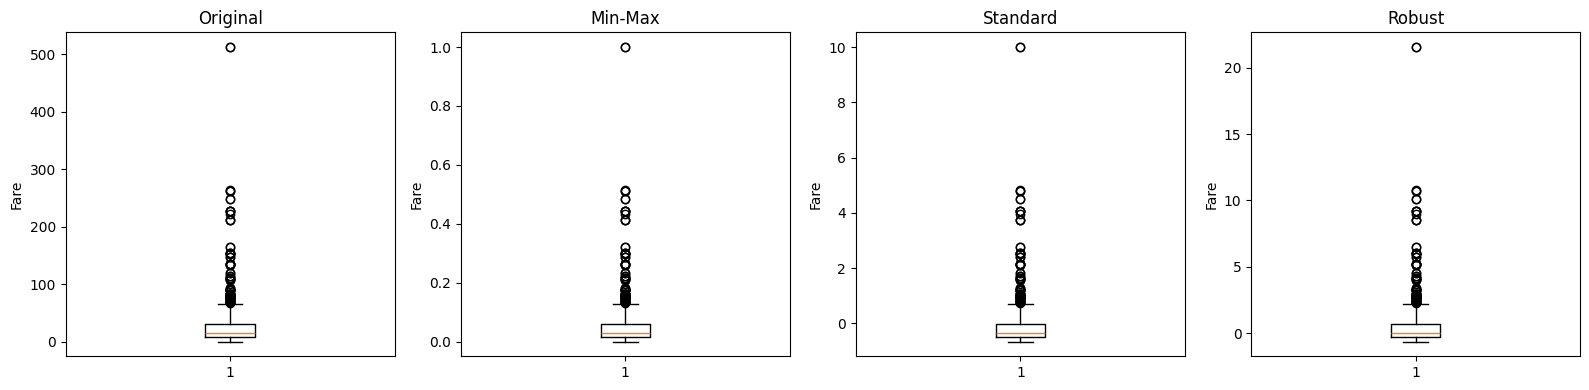

In [11]:
# Visualizamos a distribuição da tarifa antes e depois dos três escalonamentos.
# A tarifa possui valores relativamente altos e alguns valores extremos.

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].boxplot(X_train_num[:, numeric_features.index("fare")])
axes[0].set_title("Original")
axes[0].set_ylabel("Fare")

for ax, (name, result) in zip(axes[1:], scaled_results.items()):
    ax.boxplot(result["fare"])
    ax.set_title(name)
    ax.set_ylabel("Fare")

plt.tight_layout()
plt.show()


In [12]:
# Em vez de realizar cada transformação manualmente, podemos organizar o processo
# em um Pipeline.
#
# Isso reduz a chance de aplicar uma transformação de forma incorreta e deixa explícita
# a sequência que será utilizada posteriormente no treinamento do modelo.

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Formato original do treinamento: {X_train.shape}")
print(f"Formato após o pré-processamento: {X_train_processed.shape}")
print(f"Formato original do teste: {X_test.shape}")
print(f"Formato após o pré-processamento: {X_test_processed.shape}")


Formato original do treinamento: (712, 14)
Formato após o pré-processamento: (712, 19)
Formato original do teste: (179, 14)
Formato após o pré-processamento: (179, 19)


In [13]:
# O pipeline também permite recuperar os nomes das variáveis resultantes.
processed_columns = preprocessor.get_feature_names_out()

processed_df = pd.DataFrame(
    X_train_processed,
    columns=processed_columns,
    index=X_train.index
)

processed_df.head()


,numeric__age,numeric__sibsp,numeric__parch,numeric__fare,categorical__sex_female,categorical__sex_male,categorical__embarked_C,categorical__embarked_Q,categorical__embarked_S,categorical__class_First,categorical__class_Second,categorical__class_Third,categorical__who_child,categorical__who_man,categorical__who_woman,categorical__adult_male_False,categorical__adult_male_True,categorical__alone_False,categorical__alone_True
692,-0.081135,-0.465084,-0.466183,0.513812,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
481,-0.081135,-0.465084,-0.466183,-0.662563,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
527,-0.081135,-0.465084,-0.466183,3.955399,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
855,-0.887827,-0.465084,0.727782,-0.467874,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
801,0.110934,0.478335,0.727782,-0.115977,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


In [14]:
# Conferimos algumas propriedades importantes da representação final.
print(f"Valores ausentes: {np.isnan(X_train_processed).sum()}")
print(f"Total de atributos após o pré-processamento: {X_train_processed.shape[1]}")

print("\nPrimeiros atributos:")
print(processed_columns[:10])


Valores ausentes: 0
Total de atributos após o pré-processamento: 19

Primeiros atributos:
['numeric__age' 'numeric__sibsp' 'numeric__parch' 'numeric__fare'
 'categorical__sex_female' 'categorical__sex_male'
 'categorical__embarked_C' 'categorical__embarked_Q'
 'categorical__embarked_S' 'categorical__class_First']


## Reflexão

Responda individualmente. Suas respostas devem partir do que você observou nos dados e no comportamento das transformações realizadas.

1. O pipeline produziu **mais atributos do que existiam originalmente**. Escolha uma das variáveis categóricas e explique por que isso aconteceu. Em que situação esse aumento poderia se tornar um problema?

2. Observe a variável `fare` antes e depois dos três escalonamentos. **Qual transformação você escolheria para este dataset e por quê?** Sua justificativa deve utilizar uma característica observada nos dados, e não apenas a definição de cada técnica.

3. Imagine que, por engano, você tivesse executado `StandardScaler().fit_transform(X)` **antes** do `train_test_split`. O resultado do modelo poderia mudar? Explique exatamente **qual informação do teste teria entrado no treinamento**.

4. O atributo `class` contém `First`, `Second` e `Third`. Você escolheria **One-Hot Encoding ou Ordinal Encoding** para essa variável? Justifique considerando o significado da variável e o tipo de relação que o modelo poderia interpretar.

5. Suponha que uma variável categórica possua **5.000 categorias diferentes**. O One-Hot Encoding continuaria sendo sua primeira escolha? Explique o que aconteceria com a representação dos dados e indique uma alternativa que você investigaria.

6. O pré-processamento melhorou os dados ou apenas os **modificou**? Escolha uma transformação realizada nesta aula e explique o que foi ganho e o que pode ter sido perdido com ela.

7. Imagine que, depois de aplicar o pré-processamento, um colega diga: "Agora os dados estão prontos para qualquer algoritmo de IA". **Você concorda?** Dê um contraexemplo utilizando um dos algoritmos que serão estudados nas próximas aulas.


# 3. Prática Contextualizada

Cada aluno deverá aplicar as técnicas de pré-processamento estudadas a um **problema real de sua escolha**.

A aplicação deverá utilizar um dataset adequado ao problema e demonstrar que as transformações foram escolhidas de forma consciente.

### O aluno deverá

- apresentar brevemente o problema;
- apresentar o dataset e suas principais características;
- identificar quais atributos precisam de transformação;
- separar os dados antes de realizar transformações que aprendem parâmetros;
- escolher e justificar as técnicas de pré-processamento utilizadas;
- implementar as transformações;
- apresentar a representação dos dados antes e depois do pré-processamento (gráficos);
- discutir possíveis limitações ou riscos da abordagem;
- explicar como os dados preparados poderiam ser utilizados na etapa de modelagem.

A apresentação deverá demonstrar **compreensão e adaptação** das técnicas estudadas, e não apenas reprodução do notebook da aula.

O aluno selecionado para a Prática Contextualizada apresentará sua aplicação **na próxima aula**.

A atividade corresponde à **NL2 – Prática Contextualizada**:

- **70% — Professor**
- **30% — Avaliação entre pares**
